In [ ]:
!pip -q install librosa soundfile matplotlib numpy

# 1. Import i parametry

In [2]:
import os
import numpy as np
import librosa
import librosa.display
import matplotlib.pyplot as plt

SR = 16000 # częstotliwość próbkowania [Hz] — standard w ASR
N_FFT = 512 # długość okna FFT
HOP_LENGTH = 160 # przesunięcie ramki (10 ms przy 16 kHz)
N_MELS = 64 # liczba pasm mel

# 2. Wczytanie audio

In [4]:
#from google.colab import files
#uploaded = files.upload()

def wczytaj_audio(sciezka=None):
    if sciezka:
        y, sr = librosa.load(sciezka, sr=SR, mono=True)
        return y.astype(np.float32), sr
    # Sygnał syntetyczny: chirp 200 Hz -> 3000 Hz, 2 s
    y = librosa.chirp(fmin=200, fmax=3000, sr=SR, duration=2.0)
    return y.astype(np.float32), SR

PLIKI = ["samogloska.wav", "wyraz.wav", "zdanie.wav"]

nagrania = {} # słownik: nazwa pliku -> (sygnał, częstotliwość próbkowania)
for nazwa in PLIKI:
    if os.path.exists(nazwa):
        y_n, sr_n = wczytaj_audio(nazwa)
    else:
        print(f"UWAGA: brak pliku '{nazwa}' — używam sygnału syntetycznego (chirp).")
        y_n, sr_n = wczytaj_audio(None)
    nagrania[nazwa] = (y_n, sr_n)
    print(f"{nazwa}: liczba próbek = {len(y_n)}, częstotliwość próbkowania = {sr_n} Hz, czas = {len(y_n) / sr_n:.2f} s")

samogloska.wav: liczba próbek = 9318, częstotliwość próbkowania = 16000 Hz, czas = 0.58 s
wyraz.wav: liczba próbek = 11722, częstotliwość próbkowania = 16000 Hz, czas = 0.73 s
zdanie.wav: liczba próbek = 26283, częstotliwość próbkowania = 16000 Hz, czas = 1.64 s


# 3. Odsłuch (opcjonalnie)

In [5]:
from IPython.display import Audio

y_odsluch, sr_odsluch = nagrania["zdanie.wav"]
Audio(y_odsluch, rate=sr_odsluch)

# 4. Reprezentacje: log-mel i MFCC

In [6]:
def log_mel(y, sr, n_fft=N_FFT, hop_length=HOP_LENGTH, n_mels=N_MELS):
    S = librosa.feature.melspectrogram(
        y=y, sr=sr, n_fft=n_fft, hop_length=hop_length, n_mels=n_mels
    )
    return librosa.power_to_db(S, ref=np.max)

def mfcc(y, sr, n_mfcc=13):
    return librosa.feature.mfcc(
        y=y, sr=sr, n_mfcc=n_mfcc, n_fft=N_FFT, hop_length=HOP_LENGTH
    )

# Kontrola kształtów macierzy cech dla nagrania 'zdanie.wav':
y_zd, sr_zd = nagrania["zdanie.wav"]
S_db = log_mel(y_zd, sr_zd)
M = mfcc(y_zd, sr_zd)
print(f"Kształt log-mel: {S_db.shape}  (pasma mel × ramki czasowe)")
print(f"Kształt MFCC:    {M.shape}  (współczynniki × ramki czasowe)")

Kształt log-mel: (64, 165)  (pasma mel × ramki czasowe)
Kształt MFCC:    (13, 165)  (współczynniki × ramki czasowe)


# 5. Wizualizacje

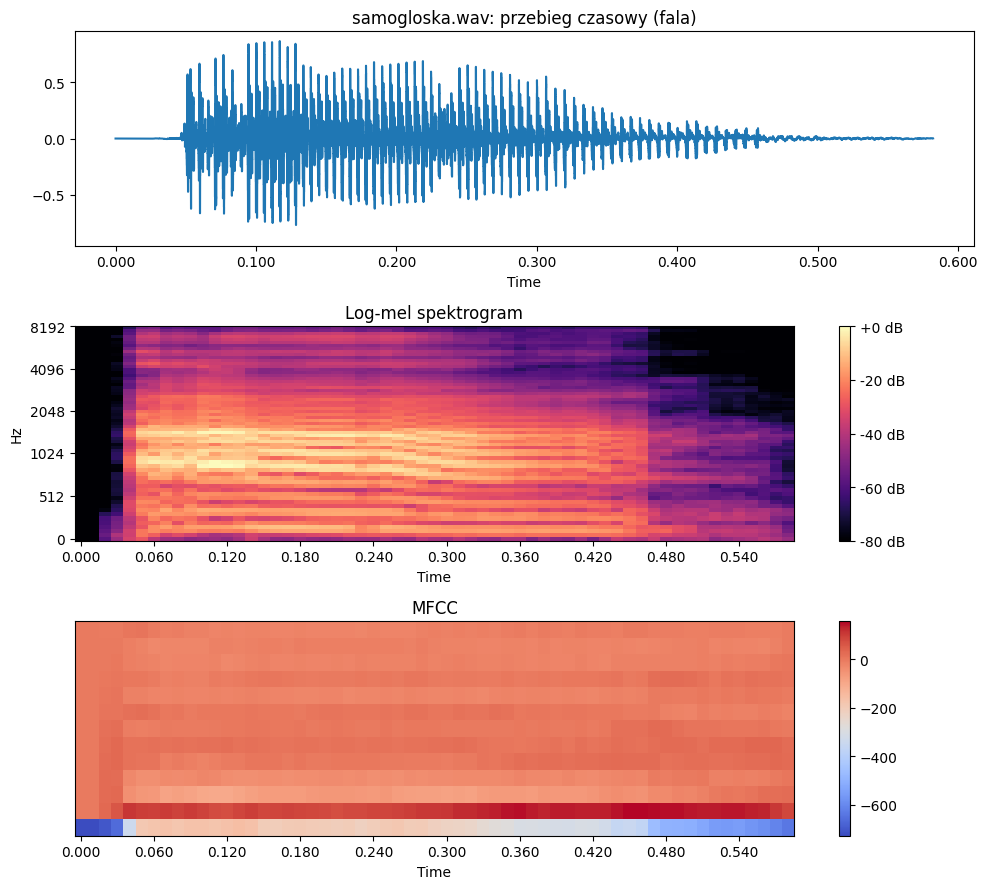

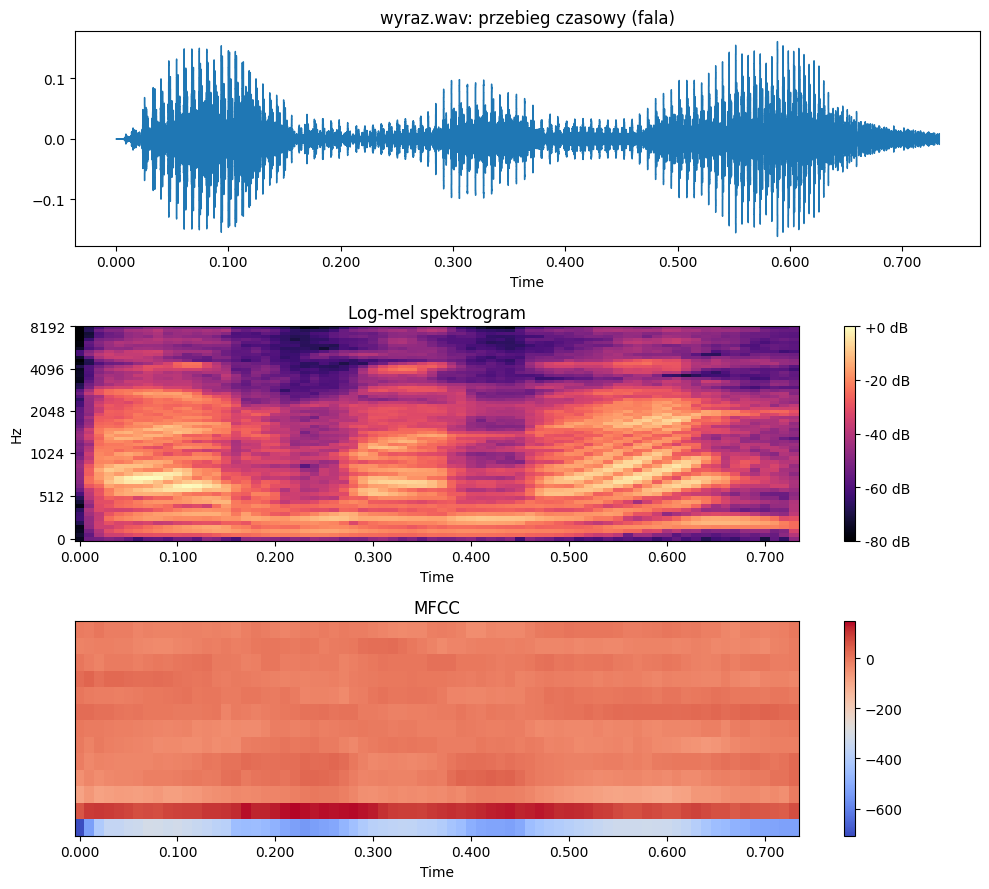

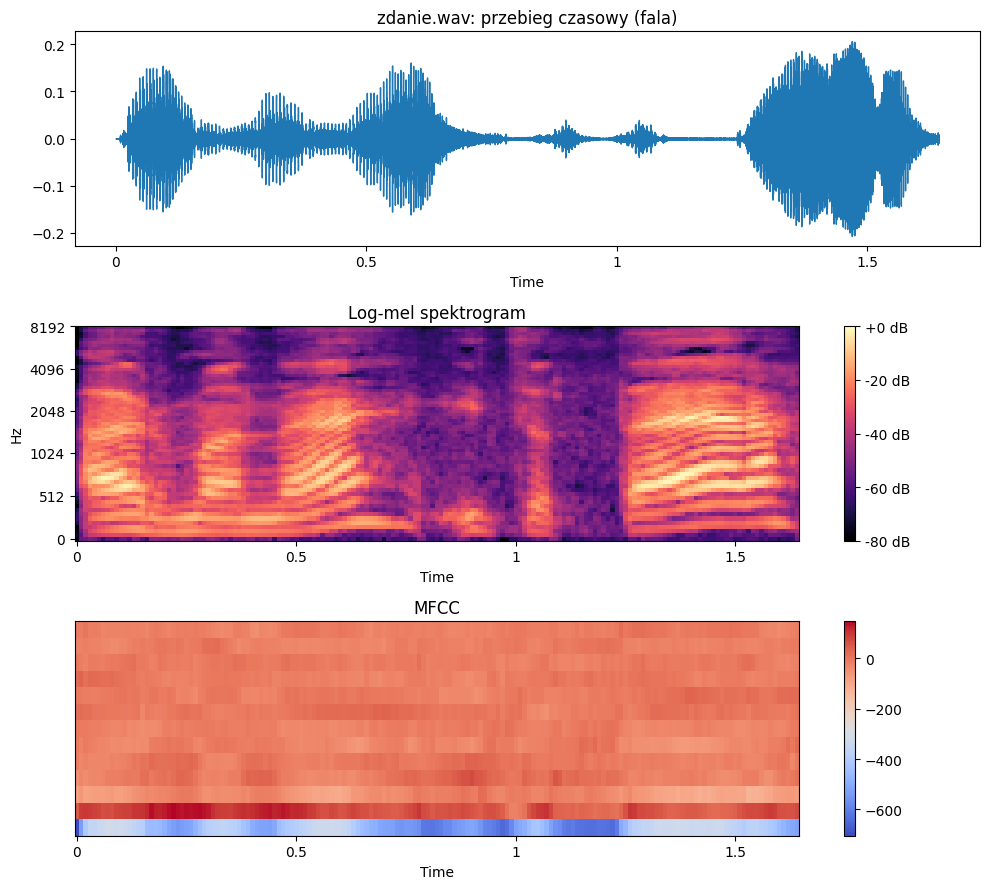

In [7]:
for nazwa, (y_n, sr_n) in nagrania.items():
    S_db = log_mel(y_n, sr_n)
    M = mfcc(y_n, sr_n)

    fig, ax = plt.subplots(3, 1, figsize=(10, 9))

    librosa.display.waveshow(y_n, sr=sr_n, ax=ax[0])
    ax[0].set_title(f"{nazwa}: przebieg czasowy (fala)")

    img1 = librosa.display.specshow(
        S_db, sr=sr_n, hop_length=HOP_LENGTH, x_axis="time", y_axis="mel", ax=ax[1]
    )
    ax[1].set_title("Log-mel spektrogram")
    fig.colorbar(img1, ax=ax[1], format="%+2.0f dB")

    img2 = librosa.display.specshow(
        M, sr=sr_n, hop_length=HOP_LENGTH, x_axis="time", ax=ax[2]
    )
    ax[2].set_title("MFCC")
    fig.colorbar(img2, ax=ax[2])

    plt.tight_layout()
    plt.show()

# 6. Eksperyment A — wpływ długości okna n_fft

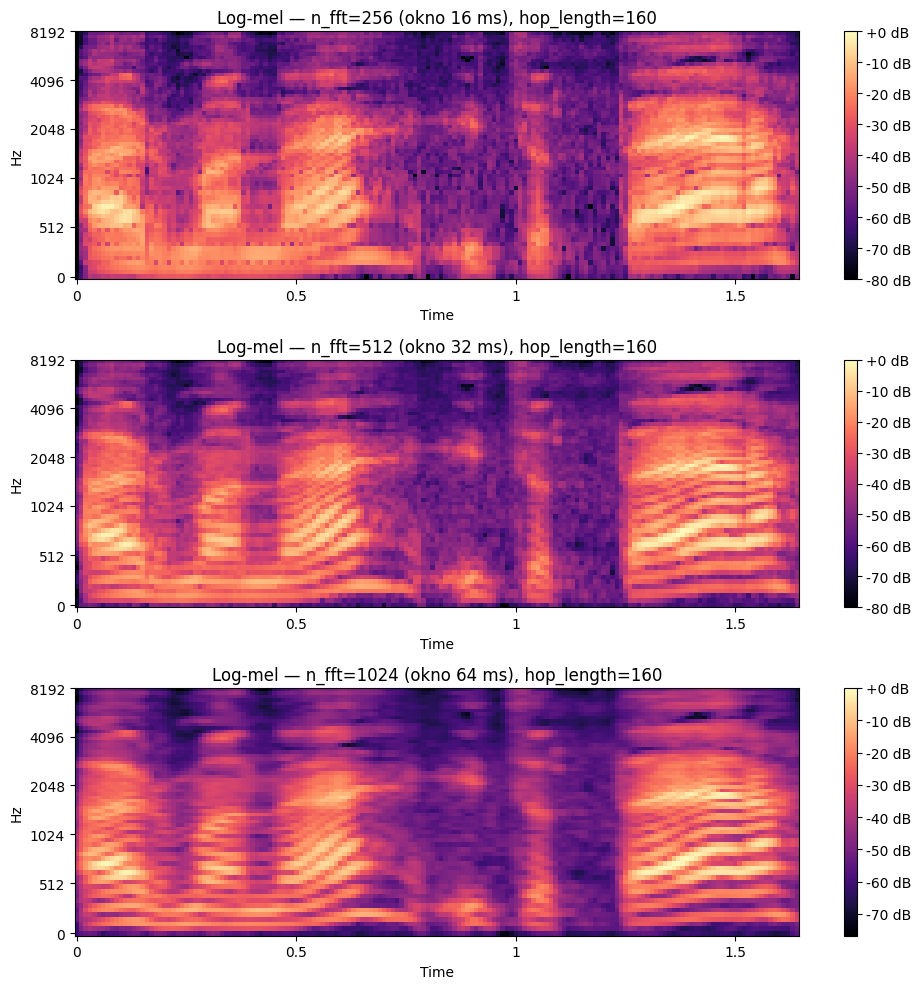

n_fft=  256 -> kształt log-mel: (64, 165)  (pasma mel: 64, ramki: 165)
n_fft=  512 -> kształt log-mel: (64, 165)  (pasma mel: 64, ramki: 165)
n_fft= 1024 -> kształt log-mel: (64, 165)  (pasma mel: 64, ramki: 165)


In [8]:
y_zd, sr_zd = nagrania["zdanie.wav"] # analizujemy jedno nagranie

N_FFT_LIST = [256, 512, 1024] # różne długości okna; stały krok HOP_LENGTH = 160

fig, ax = plt.subplots(len(N_FFT_LIST), 1, figsize=(10, 10))
ksztalty = []
for ax_i, n_fft in zip(ax, N_FFT_LIST):
    S_db = log_mel(y_zd, sr_zd, n_fft=n_fft, hop_length=HOP_LENGTH)
    ksztalty.append((n_fft, S_db.shape))
    img = librosa.display.specshow(
        S_db, sr=sr_zd, hop_length=HOP_LENGTH, x_axis="time", y_axis="mel", ax=ax_i
    )
    ax_i.set_title(
        f"Log-mel — n_fft={n_fft} (okno {n_fft / sr_zd * 1000:.0f} ms), hop_length={HOP_LENGTH}"
    )
    fig.colorbar(img, ax=ax_i, format="%+2.0f dB")

plt.tight_layout()
plt.show()

# Liczba ramek jest ta sama (stały krok); zmienia się rozdzielczość częstotliwościowa:
for n_fft, ksztalt in ksztalty:
    print(f"n_fft={n_fft:5d} -> kształt log-mel: {ksztalt}  (pasma mel: {ksztalt[0]}, ramki: {ksztalt[1]})")

# 7. Eksperyment B — wpływ kroku hop_length

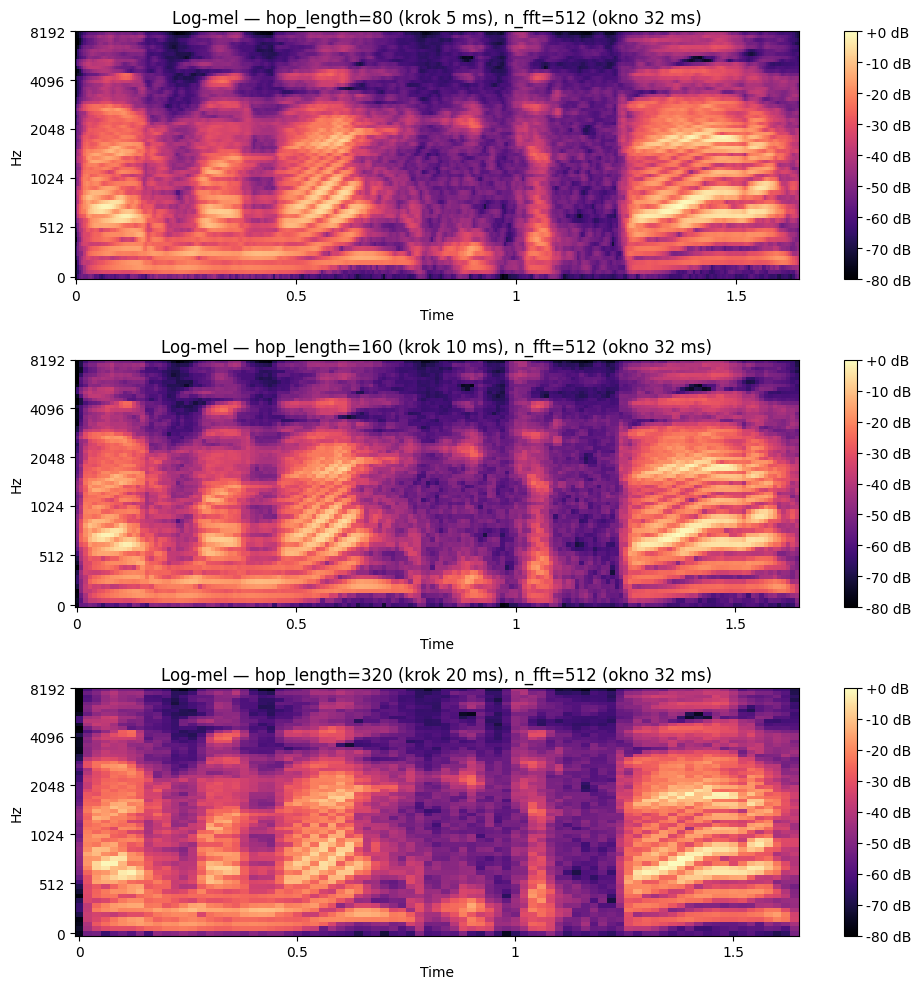

hop_length= 80 -> kształt log-mel: (64, 329)  (liczba ramek: 329)
hop_length=160 -> kształt log-mel: (64, 165)  (liczba ramek: 165)
hop_length=320 -> kształt log-mel: (64, 83)  (liczba ramek: 83)


In [9]:
y_zd, sr_zd = nagrania["zdanie.wav"] # to samo nagranie co w eksperymencie A

HOP_LIST = [80, 160, 320] # różne kroki; stałe okno N_FFT = 512

fig, ax = plt.subplots(len(HOP_LIST), 1, figsize=(10, 10))
ksztalty = []
for ax_i, hop in zip(ax, HOP_LIST):
    S_db = log_mel(y_zd, sr_zd, n_fft=N_FFT, hop_length=hop)
    ksztalty.append((hop, S_db.shape))
    img = librosa.display.specshow(
        S_db, sr=sr_zd, hop_length=hop, x_axis="time", y_axis="mel", ax=ax_i
    )
    ax_i.set_title(
        f"Log-mel — hop_length={hop} (krok {hop / sr_zd * 1000:.0f} ms), n_fft={N_FFT} (okno {N_FFT / sr_zd * 1000:.0f} ms)"
    )
    fig.colorbar(img, ax=ax_i, format="%+2.0f dB")

plt.tight_layout()
plt.show()

# Większy krok -> mniej ramek w macierzy cech (rzadsze próbkowanie czasu):
for hop, ksztalt in ksztalty:
    print(f"hop_length={hop:3d} -> kształt log-mel: {ksztalt}  (liczba ramek: {ksztalt[1]})")

# 8. Sekwencja cech dla modelu

In [10]:
S_db_zd = log_mel(y_zd, sr_zd)   # parametry domyślne: n_fft=512, hop_length=160

print(f"Log-mel [pasma mel, ramki]: {S_db_zd.shape}")
print(f"Sekwencja [ramki, cechy]:   {S_db_zd.T.shape}  — wejście dla modelu sekwencyjnego")

Log-mel [pasma mel, ramki]: (64, 165)
Sekwencja [ramki, cechy]:   (165, 64)  — wejście dla modelu sekwencyjnego
